# Recherche sémantique dans un corpus d'articles scientifiques

**INF5101 · Traitement multimédia des données · TP texte (slide 24)**

> - Importer 50 documents courts ou extraits de cours.
> - Créer des embeddings avec un modèle sentence-transformer ou une API locale/serveur.
> - Construire un petit moteur de recherche sémantique en Python.
> - Tester des questions et analyser les erreurs de récupération.

Le corpus : 50 articles scientifiques de 2 à 6 pages, 35 en anglais (arXiv) et 15 en français
(HAL), sur les quatre modalités du cours. Le cas d'usage : un étudiant pose une question et le
moteur lui indique quels articles lire.

**Principe** : chaque étape s'appuie sur une bibliothèque standard (pymupdf4llm, LangChain,
Pinecone, ranx). Le code écrit à la main se limite à ce que notre corpus exige et qu'aucune
bibliothèque ne fait : nettoyer les PDF HAL et arXiv, remonter des passages aux articles, et
annoter les questions d'évaluation.

| Section | Contenu |
| --- | --- |
| 1 | Corpus : téléchargement, vérification, description |
| 2 | Conversion des PDF en Markdown (pymupdf4llm) |
| 3 | Découpage en passages (LangChain) |
| 4 | Embeddings et base vectorielle (Pinecone) |
| 5 | Moteur de recherche : des passages aux articles |
| 6 | Évaluation (ranx) |
| 7 | Analyse des erreurs |

In [1]:
import hashlib
import json
import re
import time
import unicodedata
from collections import Counter
from dataclasses import dataclass
from pathlib import Path

import httpx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymupdf

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
PDF_DIR = DATA / "pdf"
PDF_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_colwidth", 80)

## 1. Le corpus

### 1.1 La sélection

Les 50 articles ont été choisis à la main parmi 226 candidats collectés automatiquement sur
arXiv et HAL. La méthode (requêtes, filtres, critères de choix) est décrite dans
[`docs/corpus.md`](../docs/corpus.md) et le script de collecte est
[`scripts/candidats.py`](../scripts/candidats.py).

In [2]:
selection = pd.read_csv(DATA / "selection.csv")
selection[["doc_id", "langue", "modalite", "pages", "titre"]].head(10)

,doc_id,langue,modalite,pages,titre
0,D01,en,texte,5,Typo-Robust Representation Learning for Dense Retrieval
1,D02,en,texte,6,Evaluation of BERT and ALBERT Sentence Embedding Performance on Downstream N...
2,D03,en,texte,2,S-SimCSE: Sampled Sub-networks for Contrastive Learning of Sentence Embedding
3,D04,en,texte,5,DuetRAG: Collaborative Retrieval-Augmented Generation
4,D05,en,texte,6,Pandora: Jailbreak GPTs by Retrieval Augmented Generation Poisoning
5,D06,en,texte,5,Cost-Efficient Cross-Lingual Retrieval-Augmented Generation for Low-Resource...
6,D07,en,texte,5,Finding Inverse Document Frequency Information in BERT
7,D08,en,texte,4,A study on the Interpretability of Neural Retrieval Models using DeepSHAP
8,D09,en,texte,4,A Method of Passage-Based Document Retrieval in Question Answering System
9,D10,en,image,6,Image Classification with CondenseNeXt for ARM-Based Computing Platforms


In [3]:
pd.crosstab(selection["modalite"], selection["langue"], margins=True, margins_name="total")

langue,en,fr,total
modalite,,,
audio,9,2,11
image,9,4,13
multimodal,8,3,11
texte,9,6,15
total,35,15,50


### 1.2 Téléchargement, à la main

Quelques précautions qu'une boucle naïve oublierait :

- **idempotence** : un PDF déjà présent n'est pas retéléchargé, on peut relancer la cellule ;
- **politesse** : les conditions d'utilisation d'arXiv demandent au plus une requête toutes les
  3 secondes ;
- **vérification du contenu** : un serveur peut renvoyer une page HTML (erreur, captcha) avec un
  code 200. On vérifie la signature `%PDF` au début du fichier plutôt que de faire confiance à
  l'en-tête.

In [4]:
def download(url: str, dest: Path, client: httpx.Client) -> str:
    if dest.exists():
        return "déjà présent"
    response = client.get(url)
    if response.status_code != 200:
        return f"erreur HTTP {response.status_code}"
    if not response.content.startswith(b"%PDF"):
        return "pas un PDF"
    dest.write_bytes(response.content)
    return "téléchargé"


HEADERS = {"User-Agent": "INF5101-tp1 (usage pedagogique)"}
statuses = {}
with httpx.Client(follow_redirects=True, timeout=60, headers=HEADERS) as client:
    for row in selection.itertuples():
        dest = PDF_DIR / f"{row.doc_id}.pdf"
        status = download(row.url, dest, client)
        statuses[row.doc_id] = status
        if status == "téléchargé" and row.source == "arxiv":
            time.sleep(3)

pd.Series(statuses).value_counts()

déjà présent    50
Name: count, dtype: int64

### 1.3 Version moderne : le client `arxiv`

Le paquet [`arxiv`](https://pypi.org/project/arxiv/) encapsule l'API : recherche, pagination,
respect du délai entre requêtes, téléchargement. HAL n'a pas de client Python officiel ; son API
Solr s'interroge directement en HTTP, comme dans `scripts/candidats.py`.

On l'utilise ici pour relire les métadonnées d'un article et vérifier qu'elles correspondent à
notre fichier, sans tout retélécharger.

In [5]:
import arxiv

client = arxiv.Client(delay_seconds=3)
first = selection[selection["source"] == "arxiv"].iloc[0]
paper = next(client.results(arxiv.Search(id_list=[first["source_id"]])))
print(paper.title)
print(", ".join(a.name for a in paper.authors))
print(paper.comment)
print(paper.pdf_url)
# paper.download_pdf(dirpath=PDF_DIR, filename=f"{first['doc_id']}.pdf") ferait le téléchargement.

Typo-Robust Representation Learning for Dense Retrieval
Panuthep Tasawong, Wuttikorn Ponwitayarat, Peerat Limkonchotiwat, Can Udomcharoenchaikit, Ekapol Chuangsuwanich, Sarana Nutanong
5 pages, 2 figures
https://arxiv.org/pdf/2306.10348v1


### 1.4 Vérification des PDF

Pour chaque fichier, on vérifie ce qui pourrait casser les étapes suivantes :

- **nombre réel de pages**, comparé à celui déclaré dans les métadonnées ;
- **présence d'une couche texte** : un PDF scanné n'a que des images, il faudrait de l'OCR ;
- **empreinte SHA-256**, pour garantir que le corpus ne change pas entre deux exécutions.

In [6]:
def inspect(path: Path) -> dict:
    with pymupdf.open(path) as doc:
        text = "".join(page.get_text() for page in doc)
        return {
            "pages_reelles": doc.page_count,
            "mots": len(text.split()),
            "couche_texte": len(text.strip()) > 500,
            "sha256": hashlib.sha256(path.read_bytes()).hexdigest()[:16],
        }


checks = pd.DataFrame([{"doc_id": p.stem, **inspect(p)} for p in sorted(PDF_DIR.glob("D*.pdf"))])
corpus = selection.merge(checks, on="doc_id")
corpus["ecart_pages"] = corpus["pages_reelles"] - corpus["pages"]
print(f"{len(corpus)} PDF, {corpus['couche_texte'].sum()} avec couche texte")
corpus["ecart_pages"].value_counts().sort_index()

50 PDF, 50 avec couche texte


ecart_pages
0    29
1    18
2     2
3     1
Name: count, dtype: int64

In [7]:
corpus.loc[corpus["ecart_pages"] != 0, ["doc_id", "source", "pages", "pages_reelles", "venue"]]

,doc_id,source,pages,pages_reelles,venue
0,D01,arxiv,5,8,"5 pages, 2 figures"
2,D03,arxiv,2,3,2 pages
3,D04,arxiv,5,6,5 pages
10,D11,arxiv,4,5,"4 pages content, 1 page references, 3 figures, 2 tables, to appear in ICASSP..."
24,D25,arxiv,4,5,Accepted by DCASE 2018 Workshop. 4 pages. Source code available
27,D28,arxiv,4,6,"4 pages, 1 figure"
35,D36,hal,4,5,Gretsi 2025 - XXXème Colloque Francophone de Traitement du Signal et des Images
36,D37,hal,4,5,GRETSI 2025 - Groupe de Recherche et d'Etudes de Traitement du Signal et des...
37,D38,hal,4,5,GRETSI 2023 - XXIXème Colloque Francophone de Traitement du Signal et des Im...
38,D39,hal,5,6,GRETSI 2023 - XXIXème Colloque Francophone de Traitement du Signal et des Im...


**Lecture.** Les 50 PDF ont une couche texte : aucun OCR n'est nécessaire. 21 documents ont plus
de pages que déclaré, pour deux raisons différentes :

- **les 15 articles HAL ont tous une page de plus** : HAL ajoute une page de garde (identifiant,
  date de dépôt, mention de licence) devant chaque document. Cette page ne dit rien du contenu
  et devra être retirée à l'extraction, sinon les 15 documents se ressembleront artificiellement ;
- **les écarts arXiv** viennent des références et des annexes que les auteurs ne comptent pas
  (« 4 pages content, 1 page references »). D01 passe de 5 à 8 pages à cause d'une annexe.

Aucun document ne dépasse 8 pages : le critère « article court » tient.

### 1.5 À quoi ressemble un document

Le format qu'on va devoir traiter : mise en page sur deux colonnes, en-têtes, équations,
figures, références, la page de garde de HAL et, sur arXiv, le filigrane vertical dans la marge
gauche (`arXiv:2306.10348v1 [cs.IR] 17 Jun 2023`). Chacun de ces éléments est un défi pour
l'extraction (section 2).

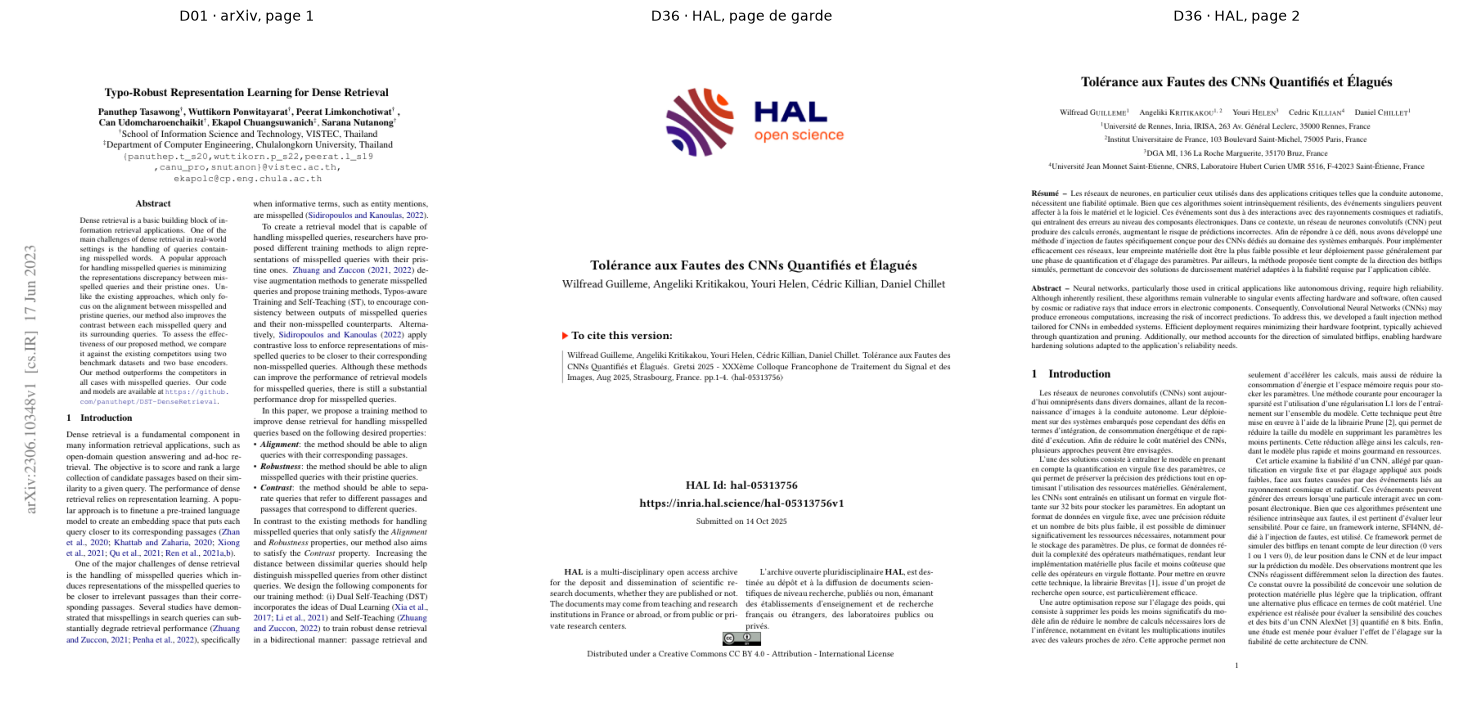

In [8]:
pages_to_show = [("D01", 0, "arXiv, page 1"), ("D36", 0, "HAL, page de garde"), ("D36", 1, "HAL, page 2")]
fig, axes = plt.subplots(1, 3, figsize=(15, 7))
for ax, (doc_id, page, label) in zip(axes, pages_to_show):
    with pymupdf.open(PDF_DIR / f"{doc_id}.pdf") as doc:
        pix = doc[page].get_pixmap(dpi=70)
    ax.imshow(np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, pix.n))
    ax.set_title(f"{doc_id} · {label}", fontsize=10)
    ax.axis("off")
plt.tight_layout()

### 1.6 Description du corpus

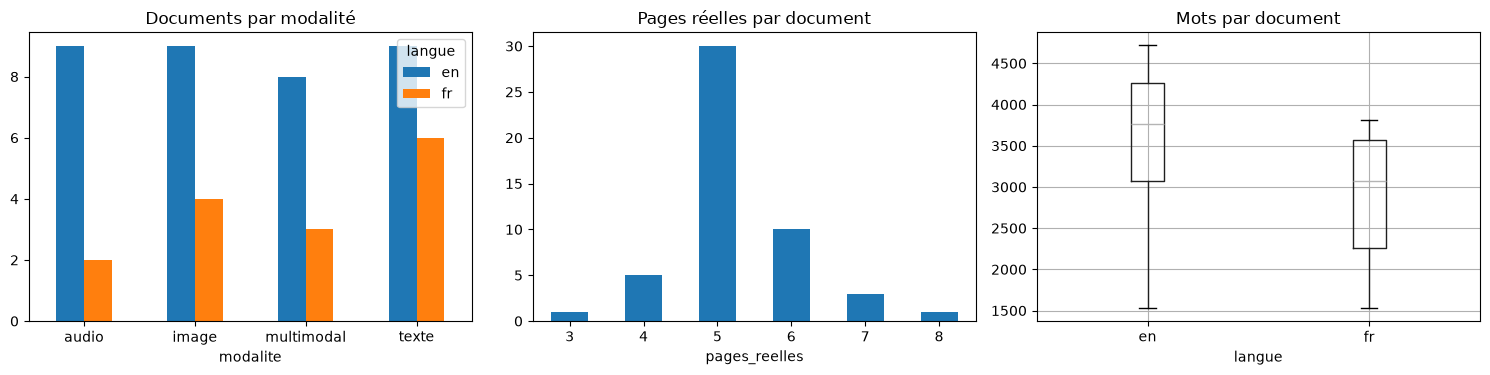

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
pd.crosstab(corpus["modalite"], corpus["langue"]).plot.bar(ax=axes[0], rot=0, title="Documents par modalité")
corpus["pages_reelles"].value_counts().sort_index().plot.bar(ax=axes[1], rot=0, title="Pages réelles par document")
corpus.boxplot(column="mots", by="langue", ax=axes[2])
axes[2].set_title("Mots par document")
fig.suptitle("")
plt.tight_layout()

In [10]:
corpus.groupby("langue")["mots"].describe().round(0)

,count,mean,std,min,25%,50%,75%,max
langue,,,,,,,,
en,35.0,3561.0,896.0,1533.0,3076.0,3762.0,4262.0,4717.0
fr,15.0,2877.0,823.0,1532.0,2254.0,3077.0,3571.0,3811.0


In [11]:
corpus.to_csv(DATA / "corpus.csv", index=False)
print(f"{len(corpus)} documents, {corpus['mots'].sum():,} mots au total".replace(",", " "))

50 documents  167 791 mots au total


## 2. Conversion des PDF en Markdown

`pymupdf4llm` convertit un PDF en Markdown : les intertitres deviennent des `#`, les tableaux
des tableaux Markdown. Cette structure servira au découpage (section 3).

Deux adaptations à notre corpus, constatées en section 1 :

- les PDF HAL commencent par une **page de garde** identique pour tous : on ne la convertit pas ;
- les **références** citent d'autres articles et fausseraient la recherche : on coupe le texte
  à leur intertitre.

In [12]:
# Pour chaque document de `corpus`, convertir le PDF avec pymupdf4llm.to_markdown(path, pages=...).
#   - PDF HAL : pages=range(1, nb_pages) pour sauter la page de garde ; sinon toutes les pages.
#   - La conversion prend environ 10 s par PDF : écrire le résultat dans data/markdown/{doc_id}.md
#     et ne pas reconvertir un fichier déjà présent.
import pymupdf4llm

MARKDOWN_DIR = DATA / "markdown"
MARKDOWN_DIR.mkdir(exist_ok=True)

# pymupdf4llm analyse la mise en page avec un petit réseau de neurones (ONNX), ce qui lui fait
# reconnaître les intertitres bien mieux que des règles. Sur une machine à 8 Go de RAM presque
# pleine, enchaîner 50 conversions dans le même processus a saturé la mémoire : le cache a été
# rempli en lançant un processus par document. Une fois le cache présent, cette cellule ne
# reconvertit rien.
for row in corpus.itertuples():
    dest = MARKDOWN_DIR / f"{row.doc_id}.md"
    if dest.exists():
        continue
    first_page = 1 if row.source == "hal" else 0
    pages = list(range(first_page, row.pages_reelles))
    dest.write_text(pymupdf4llm.to_markdown(PDF_DIR / f"{row.doc_id}.pdf", pages=pages), encoding="utf-8")

markdowns = {row.doc_id: (MARKDOWN_DIR / f"{row.doc_id}.md").read_text(encoding="utf-8") for row in corpus.itertuples()}
print(f"{len(markdowns)} documents en Markdown")

50 documents en Markdown


In [13]:
# Écrire strip_references(markdown: str) -> str : tout couper à partir de la première ligne de
# titre Markdown (#, ##…) contenant References, Références ou Bibliography.
# L'appliquer aux 50 documents, et afficher combien ont été coupés et la part de texte retirée.

# L'intertitre doit être exactement « References » (au singulier ou pluriel, en français ou en
# anglais), éventuellement numéroté et en gras : « ## **6. REFERENCES** ». Une simple recherche
# du mot couperait D08 à sa section « 5.1 Effect of reference input document ».
REFERENCES_HEADING_RE = re.compile(
    r"^#+\s*\**\s*(\d+\.?\s*)?(references?|références|bibliograph(y|ie))\s*:?\s*\**\s*$", re.I | re.M
)
# Repli quand l'intertitre n'a pas été reconnu (D36) : la première entrée de bibliographie « [7] … ».
BIBLIOGRAPHY_ENTRY_RE = re.compile(r"^(- )?\[\d+\]\s", re.M)


def strip_references(markdown: str) -> str:
    match = REFERENCES_HEADING_RE.search(markdown) or BIBLIOGRAPHY_ENTRY_RE.search(markdown)
    return markdown[: match.start()] if match else markdown


cleaned = {doc_id: strip_references(md) for doc_id, md in markdowns.items()}
removed = pd.Series({doc_id: 1 - len(cleaned[doc_id]) / len(md) for doc_id, md in markdowns.items()})
print(f"{(removed > 0).sum()} documents coupés sur {len(removed)}")
print(f"part du texte retirée : {removed.mean():.0%} en moyenne (de {removed.min():.0%} à {removed.max():.0%})")

50 documents coupés sur 50
part du texte retirée : 18% en moyenne (de 5% à 35%)


In [14]:
# Afficher les 1 500 premiers caractères du Markdown nettoyé de D21 (arXiv) et de D36 (HAL).
for doc_id in ["D21", "D36"]:
    print(f"===== {doc_id} =====")
    print(cleaned[doc_id][:1500], "\n")

===== D21 =====
# **SASV 2022: The First Spoofing-Aware Speaker Verification Challenge** 

_Jee-weon Jung_<sup>_∗,_1</sup> _, Hemlata Tak_<sup>_∗,_2</sup> _, Hye-jin Shim_<sup>3</sup> _, Hee-Soo Heo_<sup>1</sup> _, Bong-Jin Lee_<sup>1</sup> _, Soo-Whan Chung_<sup>1</sup> _, Ha-Jin Yu_<sup>3</sup> _, Nicholas Evans_<sup>2</sup> _, and Tomi Kinnunen_<sup>4</sup> 

1Naver Corporation, South Korea, 

2EURECOM, Sophia Antipolis, France, 

3School of Computer Science, University of Seoul, South Korea, 

4University of Eastern Finland, Finland 

sasv.challenge@gmail.com 

## **Abstract** 

The first spoofing-aware speaker verification (SASV) challenge aims to integrate research efforts in speaker verification and anti-spoofing. We extend the speaker verification scenario by introducing _spoofed_ trials to the usual set of target and impostor trials. In contrast to the established ASVspoof challenge where the focus is upon separate, independently optimised spoofing detection and speaker verifi

## 3. Découpage en passages

Un embedding résume un texte en un seul vecteur : plus le texte est long, plus le vecteur est
flou. On découpe donc chaque article en passages, en deux temps :

1. `MarkdownHeaderTextSplitter` : un morceau par section, l'intertitre est gardé en métadonnée ;
2. `RecursiveCharacterTextSplitter` : les sections trop longues sont recoupées, de préférence
   entre paragraphes puis entre phrases. Taille : 1 000 caractères (environ 160 mots), sous la
   limite de 507 tokens du modèle d'embedding, avec 150 caractères de chevauchement.

In [15]:
# Découper chaque Markdown nettoyé avec MarkdownHeaderTextSplitter
# (headers_to_split_on = #, ## et ###). Afficher les intertitres obtenus pour D21.
from langchain_core.documents import Document
from langchain_text_splitters import MarkdownHeaderTextSplitter, RecursiveCharacterTextSplitter

# Ce qui précède le résumé (titre, auteurs, affiliations, e-mails) n'aide pas la recherche :
# on part du résumé, qu'il soit un intertitre (« ## Abstract ») ou en ligne (« **_Abstract_ —** … »).
# (?![a-zé]) plutôt que \b : dans « _Abstract_ », le « _ » compte comme une lettre pour \b.
ABSTRACT_RE = re.compile(r"^(#+\s*)?[*_\s\d.]*(abstract|résumé)(?![a-zé])", re.I | re.M)
# pymupdf4llm garde le texte lu dans les figures et les lignes des tableaux : des fragments sans
# phrases (« (a) DPR », « |**Bona fide**|**Spoofed**| ») qui brouilleraient les embeddings.
PICTURE_TEXT_RE = re.compile(r"<!-- Start of picture text -->.*?<!-- End of picture text -->", re.S)
TABLE_ROW_RE = re.compile(r"^\|.*$", re.M)


def prepare(markdown: str) -> str:
    start = ABSTRACT_RE.search(markdown)
    markdown = markdown[start.start():] if start else markdown
    markdown = PICTURE_TEXT_RE.sub("", markdown)
    return TABLE_ROW_RE.sub("", markdown)


header_splitter = MarkdownHeaderTextSplitter(headers_to_split_on=[("#", "h1"), ("##", "h2"), ("###", "h3")])
sections = {doc_id: header_splitter.split_text(prepare(md)) for doc_id, md in cleaned.items()}

print(f"{sum(len(s) for s in sections.values())} sections au total")
for section in sections["D21"]:
    print(section.metadata, len(section.page_content), "caractères")

511 sections au total
{'h2': '**Abstract**'} 1331 caractères
{'h2': '**1. Introduction**'} 4337 caractères
{'h2': '**2. Related Works**'} 1933 caractères
{'h2': '**3. Databases, protocols and metrics**'} 283 caractères
{'h2': '**3. Databases, protocols and metrics**', 'h3': '**3.1. VoxCeleb2**'} 849 caractères
{'h2': '**3. Databases, protocols and metrics**', 'h3': '**3.2. ASVspoof 2019**'} 742 caractères
{'h2': '**3. Databases, protocols and metrics**', 'h3': '**3.3. SASV protocols**'} 746 caractères
{'h2': '**3. Databases, protocols and metrics**', 'h3': '**3.4. Metrics**'} 1509 caractères
{'h2': '**4. SASV baseline solutions**'} 85 caractères
{'h2': '**4. SASV baseline solutions**', 'h3': '**4.1. ASV and CM sub-systems**'} 1388 caractères
{'h2': '**4. SASV baseline solutions**', 'h3': '**4.2. Baselines**'} 1684 caractères
{'h2': '**5. Challenge results**'} 2280 caractères
{'h2': '**6. Solution strategies**'} 1808 caractères
{'h2': '**7. Discussion and Conclusions**'} 1848 caractères

In [16]:
# Recouper avec RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=150).split_documents(...).

# Le découpeur essaie dans l'ordre : paragraphes (« \n\n »), lignes, espaces, puis caractères.
# Il ne coupe donc au milieu d'une phrase qu'en dernier recours. Le chevauchement de 150
# caractères répète la fin d'un passage au début du suivant, pour qu'une idée à cheval sur la
# coupure reste trouvable.
text_splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=150)
pieces = {doc_id: text_splitter.split_documents(doc_sections) for doc_id, doc_sections in sections.items()}
print(f"{sum(len(p) for p in pieces.values())} passages")

1255 passages


In [17]:
# Compléter chaque passage (Document LangChain) :
#   - metadata : doc_id, titre, langue, modalite, url (depuis `corpus`), section, chunk_id ("D01-003") ;
#   - page_content préfixé par "titre › section\n\n" : un passage isolé (« Our method
#     outperforms… ») ne dit pas de quoi il parle, le préfixe lui donne son contexte.
# Rassembler tous les passages dans une liste `chunks`.
# Les remerciements (financements, collègues) ne parlent pas du sujet de l'article.
ACKNOWLEDGMENTS_RE = re.compile(r"acknowledge?ments?|remerciements", re.I)
meta = corpus.set_index("doc_id")
chunks = []
for doc_id, doc_pieces in pieces.items():
    titre = meta.loc[doc_id, "titre"]
    for i, piece in enumerate(doc_pieces):
        # L'intertitre le plus précis disponible. Un passage sans intertitre est le résumé en
        # ligne (« Abstract — … »), qui précède le premier intertitre.
        section = piece.metadata.get("h3") or piece.metadata.get("h2") or piece.metadata.get("h1") or "Résumé"
        section = re.sub(r"[*_]", "", section).strip()
        if ACKNOWLEDGMENTS_RE.search(section):
            continue
        chunks.append(Document(
            page_content=f"{titre} › {section}\n\n{piece.page_content}",
            metadata={
                "chunk_id": f"{doc_id}-{i:03d}",
                "doc_id": doc_id,
                "titre": titre,
                "langue": meta.loc[doc_id, "langue"],
                "modalite": meta.loc[doc_id, "modalite"],
                "url": meta.loc[doc_id, "url"],
                "section": section,
            },
        ))

print(chunks[1].metadata)
print(chunks[1].page_content[:400])

{'chunk_id': 'D01-001', 'doc_id': 'D01', 'titre': 'Typo-Robust Representation Learning for Dense Retrieval', 'langue': 'en', 'modalite': 'texte', 'url': 'https://arxiv.org/pdf/2306.10348v1', 'section': '1 Introduction'}
Typo-Robust Representation Learning for Dense Retrieval › 1 Introduction

Dense retrieval is a fundamental component in many information retrieval applications, such as open-domain question answering and ad-hoc retrieval. The objective is to score and rank a large collection of candidate passages based on their similarity to a given query. The performance of dense retrieval relies on representatio


1242 passages
min     10.0
mean    24.8
max     44.0
dtype: float64
premier passage hors résumé : []


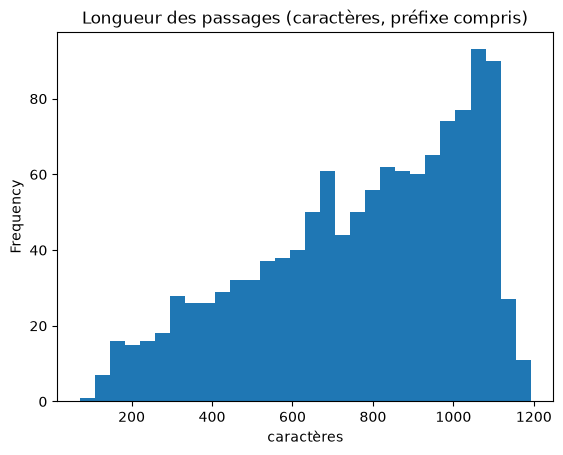

In [18]:
# Contrôler : nombre total de passages, histogramme de leur longueur en caractères,
# nombre de passages par document (min, moyenne, max).
chunks_df = pd.DataFrame([{**c.metadata, "caracteres": len(c.page_content)} for c in chunks])
print(f"{len(chunks_df)} passages")
print(chunks_df.groupby("doc_id").size().describe().loc[["min", "mean", "max"]].round(1))
# Chaque article doit commencer par son résumé : sinon, l'en-tête (auteurs, affiliations) est resté.
first_sections = chunks_df.groupby("doc_id")["section"].first()
print("premier passage hors résumé :", list(first_sections[~first_sections.str.contains("abstract|résumé", case=False)].index))

chunks_df["caracteres"].plot.hist(bins=30, title="Longueur des passages (caractères, préfixe compris)")
plt.xlabel("caractères")
plt.show()

## 4. Embeddings et base vectorielle Pinecone

- **Modèle** : `multilingual-e5-large`, hébergé par Pinecone (*Pinecone Inference*). Il est
  multilingue, donc une question en français peut retrouver un article en anglais, et il tourne
  sur les serveurs de Pinecone plutôt que sur notre machine.
- **Base** : un index Pinecone *serverless* de dimension 1024, en similarité cosinus.

La clé d'API se met dans `.env` (fichier ignoré par Git) : `PINECONE_API_KEY=...`.

In [19]:
# Charger la clé avec dotenv.load_dotenv(ROOT / ".env"), puis créer le client pinecone.Pinecone().
from dotenv import load_dotenv
from langchain_pinecone import PineconeEmbeddings, PineconeVectorStore
from pinecone import Pinecone, ServerlessSpec

# Le client lit la clé dans la variable d'environnement PINECONE_API_KEY : elle n'apparaît
# jamais dans le notebook, qui peut donc être publié tel quel.
load_dotenv(ROOT / ".env")
pc = Pinecone()
print("index existants :", [index.name for index in pc.list_indexes()])

C:\Users\GSI\Documents\Master 2\tp1-recherche-semantique\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


index existants : ['pinecone-datacamp', 'dotproduct-index', 'n8n-agent', 'inf5101-articles']


In [20]:
# Créer l'index "inf5101-articles" s'il n'existe pas déjà :
# dimension=1024, metric="cosine", spec=ServerlessSpec(cloud="aws", region="us-east-1").
INDEX_NAME = "inf5101-articles"

if not pc.has_index(INDEX_NAME):
    # 1024 = taille des vecteurs produits par multilingual-e5-large. « Serverless » : Pinecone
    # gère les serveurs et ne facture que le stockage et les requêtes ; l'offre gratuite
    # n'existe que dans la région aws / us-east-1.
    pc.create_index(
        name=INDEX_NAME,
        dimension=1024,
        metric="cosine",
        spec=ServerlessSpec(cloud="aws", region="us-east-1"),
    )
index = pc.Index(INDEX_NAME)
print(pc.describe_index(INDEX_NAME))

{'deletion_protection': 'disabled',
 'dimension': 1024,
 'host': 'inf5101-articles-g92xtkd.svc.aped-4627-b74a.pinecone.io',
 'metric': 'cosine',
 'name': 'inf5101-articles',
 'spec': {'serverless': {'cloud': 'aws', 'region': 'us-east-1'}},
 'status': {'ready': True, 'state': 'Ready'},
 'tags': None,
 'vector_type': 'dense'}


In [21]:
# embeddings = PineconeEmbeddings(model="multilingual-e5-large").
# Test : encoder une phrase en français et sa traduction anglaise, puis une phrase sans rapport,
# et comparer les similarités cosinus.

# Le modèle tourne chez Pinecone : rien de lourd n'est chargé sur notre machine. Il distingue
# les requêtes des passages (préfixes « query: » et « passage: » de la famille e5) : LangChain
# s'en charge, embed_query pour une question, embed_documents pour des passages.
embeddings = PineconeEmbeddings(model="multilingual-e5-large")

sentences = [
    "La reconnaissance automatique de la parole transcrit un signal audio en texte.",
    "Automatic speech recognition transcribes an audio signal into text.",
    "Les réseaux convolutifs classent des images satellites.",
]
vectors = np.array(embeddings.embed_documents(sentences))
vectors /= np.linalg.norm(vectors, axis=1, keepdims=True)
similarity = vectors @ vectors.T
print(f"dimension : {vectors.shape[1]}")
print(f"français / sa traduction anglaise : {similarity[0, 1]:.3f}")
print(f"français / phrase sans rapport     : {similarity[0, 2]:.3f}")

dimension : 1024
français / sa traduction anglaise : 0.933
français / phrase sans rapport     : 0.855


**Lecture.** La phrase et sa traduction sont presque confondues (0,93) : le modèle place le français et l'anglais dans le même espace, ce qui rend la recherche cross-lingue possible. Mais une phrase sans rapport obtient encore 0,85 : avec les modèles e5, toutes les similarités sont tassées dans le haut de l'échelle. Un score n'a donc de sens que **comparé aux autres**, jamais dans l'absolu. On s'en souviendra pour fixer un seuil d'abstention (section 7).

In [22]:
# vectorstore = PineconeVectorStore(index=..., embedding=embeddings).
# Y ajouter `chunks` avec ids = les chunk_id : relancer la cellule écrase les passages au lieu
# de les dupliquer. Vérifier ensuite le nombre de vecteurs avec index.describe_index_stats().
vectorstore = PineconeVectorStore(index=index, embedding=embeddings)

# L'envoi calcule les embeddings chez Pinecone, ce qui consomme du quota gratuit : on ne le
# refait que si l'index ne contient pas déjà tous les passages.
if index.describe_index_stats().total_vector_count < len(chunks):
    BATCH = 96  # taille de lot maximale acceptée par le modèle d'embedding de Pinecone
    for start in range(0, len(chunks), BATCH):
        batch = chunks[start:start + BATCH]
        vectorstore.add_documents(batch, ids=[c.metadata["chunk_id"] for c in batch])
        # L'offre gratuite limite le nombre de tokens encodés par minute : on espace les lots.
        time.sleep(5)

# Les statistiques de l'index se mettent à jour avec quelques secondes de retard.
time.sleep(10)
print(index.describe_index_stats())

{'dimension': 1024,
 'index_fullness': 0.0,
 'metric': 'cosine',
 'namespaces': {'': {'vector_count': 1242}},
 'total_vector_count': 1242,
 'vector_type': 'dense'}


## 5. Moteur de recherche

Pinecone renvoie des **passages**. L'étudiant, lui, veut savoir quels **articles** lire : on
regroupe les passages par article, le score d'un article est celui de son meilleur passage, et ce
passage sert de justification affichée.

In [23]:
# vectorstore.similarity_search_with_score sur trois questions : une en français, une en anglais,
# et une en français dont la réponse est un article anglais.
# Afficher pour chaque passage : score, doc_id, section, début du texte.
QUESTIONS = [
    "Comment rendre un réseau de neurones embarqué robuste aux fautes matérielles ?",  # réponse attendue : D36 (fr)
    "How can a speaker verification system resist spoofing attacks?",  # D21 (en)
    "Comment améliorer la reconnaissance de caractères sur des images de mauvaise qualité ?",  # D16, D17 (en)
]

for question in QUESTIONS:
    print(f"\n>>> {question}")
    for doc, score in vectorstore.similarity_search_with_score(question, k=5):
        # Le page_content commence par le préfixe « titre › section » : on affiche le texte après.
        text = doc.page_content.split("\n\n", 1)[-1]
        print(f"{score:.3f}  {doc.metadata['doc_id']}  {doc.metadata['section'][:30]:<30}  {text[:70]}")


>>> Comment rendre un réseau de neurones embarqué robuste aux fautes matérielles ?


0.879  D36  Résumé                          **Résumé –** Les réseaux de neurones, en particulier ceux utilisés dan
0.860  D36  2 État de l’art                 Les approches classiques de protection matérielle contre les fautes re
0.858  D36  Résumé                          **Abstract –** Neural networks, particularly those used in critical ap
0.857  D36  1 Introduction                  Cet article examine la fiabilité d’un CNN, allégé par quantification e
0.855  D36  2 État de l’art                 Concernant la résilience des CNN, des travaux existants évaluent la to

>>> How can a speaker verification system resist spoofing attacks?


0.883  D21  1. Introduction                 The resistance of ASV systems to spoofing attacks has been studied onl
0.863  D21  1. Introduction                 Automatic speaker verification (ASV) systems determine whether or not 
0.860  D21  Abstract                        **Index Terms** : spoofing-aware speaker verification, audio spoofing 
0.859  D21  1. Introduction                 While the combination of CM and ASV sub-systems have the potential to 
0.859  D21  Abstract                        SASV solutions. When assessed with target, bona fide non-target and sp

>>> Comment améliorer la reconnaissance de caractères sur des images de mauvaise qualité ?


0.857  D16  Résumé                          **_Abstract_ —Text image super-resolution is a challenging yet open re
0.856  D38  1 Introduction                  De nombreuses tâches de haut niveau en vision par ordinateur, telles q
0.848  D16  III. EXPERIMENTST               **Datasets.** We use the _ICDAR2015 TextSR dataset_ [3] provided by th
0.847  D38  4 Conclusion                    Dans ce travail, nous avons proposé des améliorations au modèle Horn-R
0.847  D38  Résumé                          **Résumé –** Dans ce travail, nous étudions la restauration d’images à


In [24]:
# Écrire search_articles(question: str, k_passages: int = 20, k_articles: int = 5) -> pd.DataFrame :
# récupérer k_passages passages, garder le meilleur passage de chaque doc_id, renvoyer les
# k_articles meilleurs articles (doc_id, titre, langue, score, section et texte du meilleur passage).


def search_articles(question: str, k_passages: int = 60, k_articles: int = 5) -> pd.DataFrame:
    # On demande bien plus de passages que d'articles voulus : un article très pertinent occupe
    # souvent toutes les premières places. Avec 20 passages, la question sur le spoofing ne
    # renvoyait qu'un seul article, D21, qui avait les 20 meilleurs passages.
    results = vectorstore.similarity_search_with_score(question, k=k_passages)
    rows = pd.DataFrame([
        {
            "doc_id": doc.metadata["doc_id"],
            "titre": doc.metadata["titre"],
            "langue": doc.metadata["langue"],
            "score": round(score, 3),
            "section": doc.metadata["section"],
            "passage": doc.page_content.split("\n\n", 1)[-1],
        }
        for doc, score in results
    ])
    # Pinecone renvoie les passages du plus proche au moins proche : la première occurrence d'un
    # article est son meilleur passage. Score de l'article = score de ce passage (max).
    return rows.drop_duplicates("doc_id").head(k_articles).reset_index(drop=True)

In [25]:
# Tester search_articles sur les trois questions précédentes.
for question in QUESTIONS:
    print(f"\n>>> {question}")
    display(search_articles(question)[["doc_id", "langue", "score", "titre", "section"]])


>>> Comment rendre un réseau de neurones embarqué robuste aux fautes matérielles ?


,doc_id,langue,score,titre,section
0,D36,fr,0.879,Tolérance aux Fautes des CNNs Quantifiés et Élagués,Résumé
1,D49,fr,0.845,Oubli Catastrophique et Modèles Neuronaux de Recherche d'Information,2.1. Protocole expérimental
2,D39,fr,0.845,Compression quasi sans perte d'images satellites par filtrage de résidus,Résumé
3,D38,fr,0.844,Illumination colorée et information commune pour le modèle Horn-Retinex en r...,1 Introduction
4,D40,fr,0.834,Quantification optimisée de l'espace latent en codage audio neuronal,Résumé



>>> How can a speaker verification system resist spoofing attacks?


,doc_id,langue,score,titre,section
0,D21,en,0.883,SASV 2022: The First Spoofing-Aware Speaker Verification Challenge,1. Introduction
1,D20,en,0.814,Dynamic Latency for CTC-Based Streaming Automatic Speech Recognition With Em...,3.1. Experimental Setup
2,D35,en,0.814,Data leakage in cross-modal retrieval training: A case study,3.2. Detecting duplicates and overlapping recordings
3,D31,en,0.804,Learning Contextually Fused Audio-visual Representations for Audio-visual Sp...,3.1. Pre-training
4,D41,fr,0.804,Déréverbération non-supervisée de la parole par modèle hybride,Résumé



>>> Comment améliorer la reconnaissance de caractères sur des images de mauvaise qualité ?


,doc_id,langue,score,titre,section
0,D16,en,0.857,Boosting Optical Character Recognition: A Super-Resolution Approach,Résumé
1,D38,fr,0.856,Illumination colorée et information commune pour le modèle Horn-Retinex en r...,1 Introduction
2,D43,fr,0.847,Vers une approche inclusive de description multimédia pour le patrimoine,Résumé
3,D17,en,0.846,Image preprocessing and modified adaptive thresholding for improving OCR,Abstract:
4,D39,fr,0.837,Compression quasi sans perte d'images satellites par filtrage de résidus,5 Conclusion


**Lecture.**

- Le bon article est en tête pour les trois questions, y compris en **cross-lingue** : la question française sur la reconnaissance de caractères trouve l'article anglais D16.
- Mais on voit déjà un **biais de langue** : derrière D16, l'article français D38 (restauration d'images, sans rapport avec l'OCR) passe devant l'article anglais D17, qui traite pourtant directement le sujet. Une question française favorise les textes français. L'évaluation (section 6) mesurera l'ampleur de ce biais avec des questions cross-lingues dédiées.
- Les scores des articles 2 à 5 sont très proches (0,84 à 0,85) : comme vu en 4.3, c'est l'**écart** avec le premier qui est informatif, pas la valeur.

## 6. Évaluation

On mesure le moteur sur des questions annotées à la main : pour chaque question, les articles
qui y répondent. Types de questions : **factuelle** (vocabulaire de l'article), **paraphrase**
(autres mots), **cross-lingue** (question française, article anglais ou l'inverse), **hors
corpus** (aucun article ne répond).

Métriques, calculées avec `ranx` :

- **Hit@1**, **Hit@5** : un bon article est-il en tête, dans les cinq premiers ?
- **MRR@10** : à quel rang apparaît le premier bon article (1, puis 1/2, 1/3…) ;
- **nDCG@10** : qualité de tout le classement quand plusieurs articles sont pertinents.

In [26]:
# Charger data/questions.csv : question_id, question, langue, type, articles_pertinents
# (doc_id séparés par « ; », vide pour les questions hors corpus).
# Afficher le nombre de questions par type et par langue.
questions = pd.read_csv(DATA / "questions.csv", dtype=str).fillna("")
pd.crosstab(questions["type"], questions["langue"], margins=True, margins_name="total")

langue,en,fr,total
type,,,
cross-lingue,3,7,10
factuelle,8,4,12
hors_corpus,4,4,8
paraphrase,8,2,10
total,23,17,40


In [27]:
# Construire ranx.Qrels (articles pertinents de chaque question, hors questions hors corpus)
# et ranx.Run (scores des articles renvoyés par search_articles pour chaque question).
from ranx import Qrels, Run, compare, evaluate

# Qrels = la vérité terrain : pour chaque question, les articles pertinents (pertinence 1).
# Les questions hors corpus n'ont aucun article pertinent : elles sont évaluées à part (section 7).
answerable = questions[questions["type"] != "hors_corpus"]
qrels = Qrels({
    row.question_id: {doc_id: 1 for doc_id in row.articles_pertinents.split(";")}
    for row in answerable.itertuples()
})

# On garde les résultats de toutes les questions, hors corpus comprises, pour la section 7.
results = {row.question_id: search_articles(row.question, k_articles=10) for row in questions.itertuples()}

# Run = ce que le moteur a renvoyé : pour chaque question, un score par article.
run_pinecone = Run(
    {qid: dict(zip(results[qid]["doc_id"], results[qid]["score"])) for qid in answerable["question_id"]},
    name="pinecone-e5",
)
print(f"{len(answerable)} questions évaluées, {len(questions) - len(answerable)} hors corpus mises de côté")

32 questions évaluées, 8 hors corpus mises de côté


In [28]:
# ranx.evaluate(qrels, run, ["hit_rate@1", "hit_rate@5", "mrr@10", "ndcg@10"]) :
# sur l'ensemble, puis par type de question.
METRICS = ["hit_rate@1", "hit_rate@5", "mrr@10", "ndcg@10"]


def evaluate_by_type(run: Run) -> pd.DataFrame:
    rows = {"ensemble": evaluate(qrels, run, METRICS)}
    for question_type, group in answerable.groupby("type"):
        ids = set(group["question_id"])
        # ranx évalue les questions présentes dans les Qrels : on en construit un sous-ensemble par type.
        sub_qrels = Qrels({qid: rels for qid, rels in qrels.to_dict().items() if qid in ids})
        sub_run = Run({qid: scores for qid, scores in run.to_dict().items() if qid in ids})
        rows[f"{question_type} ({len(ids)})"] = evaluate(sub_qrels, sub_run, METRICS)
    return pd.DataFrame(rows).T.round(3)


evaluate_by_type(run_pinecone)

C:\Users\GSI\Documents\Master 2\tp1-recherche-semantique\.venv\Lib\site-packages\ranx\metrics\hit_rate.py:38: NumbaTypeSafetyWarning: unsafe cast from uint64 to int64. Precision may be lost.
  scores[i] = _hit_rate(qrels[i], run[i], k, rel_lvl)


,hit_rate@1,hit_rate@5,mrr@10,ndcg@10
ensemble,0.938,1.0,0.959,0.966
cross-lingue (10),0.800,1.0,0.870,0.891
factuelle (12),1.000,1.0,1.000,1.000
paraphrase (10),1.000,1.0,1.000,1.000


In [29]:
# Base de comparaison lexicale : BM25 (bibliothèque bm25s) sur les mêmes passages, avec le même
# regroupement par article. ranx.compare(qrels, runs=[run_bm25, run_pinecone], ...) affiche les
# deux côte à côte avec un test de significativité.
import bm25s

# BM25 compte les mots communs entre la question et le passage, pondérés par leur rareté :
# c'est la référence des moteurs classiques. Sans embeddings, il ne peut ni rapprocher deux
# synonymes, ni relier une question française à un article anglais.
retriever = bm25s.BM25()
retriever.index(bm25s.tokenize([c.page_content for c in chunks], show_progress=False), show_progress=False)


def bm25_articles(question: str, k_passages: int = 60, k_articles: int = 10) -> dict[str, float]:
    ids, scores = retriever.retrieve(bm25s.tokenize(question, show_progress=False), k=k_passages, show_progress=False)
    best = {}
    for idx, score in zip(ids[0], scores[0]):
        doc_id = chunks[idx].metadata["doc_id"]
        best.setdefault(doc_id, float(score))  # passages triés : le premier vu est le meilleur
    return dict(list(best.items())[:k_articles])


run_bm25 = Run({row.question_id: bm25_articles(row.question) for row in answerable.itertuples()}, name="bm25")
display(evaluate_by_type(run_bm25))

# Test de Student apparié sur les questions : les exposants du rapport signalent les écarts
# significatifs (p < 0,05) entre les deux moteurs.
compare(qrels, runs=[run_bm25, run_pinecone], metrics=METRICS, max_p=0.05)

,hit_rate@1,hit_rate@5,mrr@10,ndcg@10
ensemble,0.688,0.781,0.734,0.749
cross-lingue (10),0.300,0.400,0.333,0.350
factuelle (12),1.000,1.000,1.000,1.000
paraphrase (10),0.700,0.900,0.817,0.848


#    Model        Hit Rate@1    Hit Rate@5    MRR@10    NDCG@10
---  -----------  ------------  ------------  --------  ---------
a    bm25         0.688         0.781         0.734     0.749
b    pinecone-e5  0.938ᵃ        1.000ᵃ        0.959ᵃ    0.966ᵃ

**Lecture.**

| | Hit@1 | Hit@5 | MRR@10 | nDCG@10 |
| --- | --- | --- | --- | --- |
| BM25 (lexical) | 0,69 | 0,78 | 0,73 | 0,75 |
| **Pinecone + multilingual-e5-large** | **0,94** | **1,00** | **0,96** | **0,97** |

- **Le moteur sémantique domine BM25**, et l'écart est significatif sur les quatre métriques
  (test de Student apparié, p < 0,05). Le bon article est toujours dans les cinq premiers.
- **Sur les questions factuelles**, qui reprennent le vocabulaire des articles, les deux moteurs
  font jeu égal (1,00) : l'avantage des embeddings n'apparaît que quand les mots changent.
- **Sur les paraphrases**, BM25 tombe à 0,70 en Hit@1, le moteur sémantique reste à 1,00 : il
  relie « typos » à *misspelled*, « drone footage » à *UAV*.
- **Le cross-lingue sépare le plus les deux moteurs** : BM25 s'effondre (0,30), puisqu'il ne
  partage aucun mot entre une question française et un article anglais. Le moteur sémantique
  reste à 0,80, mais c'est sa catégorie la plus faible : ses deux erreurs (C05, C06) sont des
  questions françaises où un article **français** hors sujet passe devant le bon article anglais.
  C'est le biais de langue déjà repéré en section 5, analysé en section 7.

**Limites de cette évaluation.** 32 questions, rédigées par nous à partir des résumés : les
paraphrases à 100 % montrent qu'elles restent sans doute trop proches des articles. Des questions
posées par de vrais étudiants seraient un test plus dur.

## 7. Analyse des erreurs

Les chiffres disent combien le moteur se trompe ; cette section dit **pourquoi**.

In [30]:
# Lister les questions où le premier article renvoyé n'est pas pertinent :
# question, type, article attendu, article obtenu, score, passage qui a trompé le moteur.


In [31]:
# Pour chaque erreur, noter une cause dans une colonne (par exemple : articles voisins,
# vocabulaire absent du corpus, question ambiguë, extraction défaillante), puis compter par cause.


In [32]:
# Questions hors corpus : comparer la distribution du meilleur score (histogramme) avec celle
# des questions qui ont une réponse, et chercher un seuil sous lequel le moteur répond
# « aucun article de ce corpus ne traite ce sujet ».
